# Detection examples

This notebook samples validation images and creates mosaics of the original images and the corresponding YOLO26m predictions. It also generates detection examples for an external image and two frames from the rescue simulation video.

The preview excludes filenames associated with synthetic images or uncertain sources (`Gemini_`, `freepik`, `imagem_`, `image_` and `20250924_`). Review the preview because the dataset has limited per-image provenance.

The validation mosaic uses `models/yolov26m/weights/best.pt` at 640 px and a confidence threshold of **0.70**. The external image and video frames use **0.25**. Automatic selection favors confident predictions that match annotations at IoU ≥ 0.45 and prioritizes class diversity. These examples illustrate model behavior.

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dataset/data.yaml').is_file())
sys.path.insert(0, str(root / 'src'))
from evaluation.plotting.detection_figures import lottery, preview_sheet, generate, OUTPUT_DIR
from IPython.display import display, Image

## Preview validation images

Run this cell to sample 12 numbered images. Run it again for a different preview. The preview step reads dataset images and labels without loading the model.

Seed: 14170893132125166831


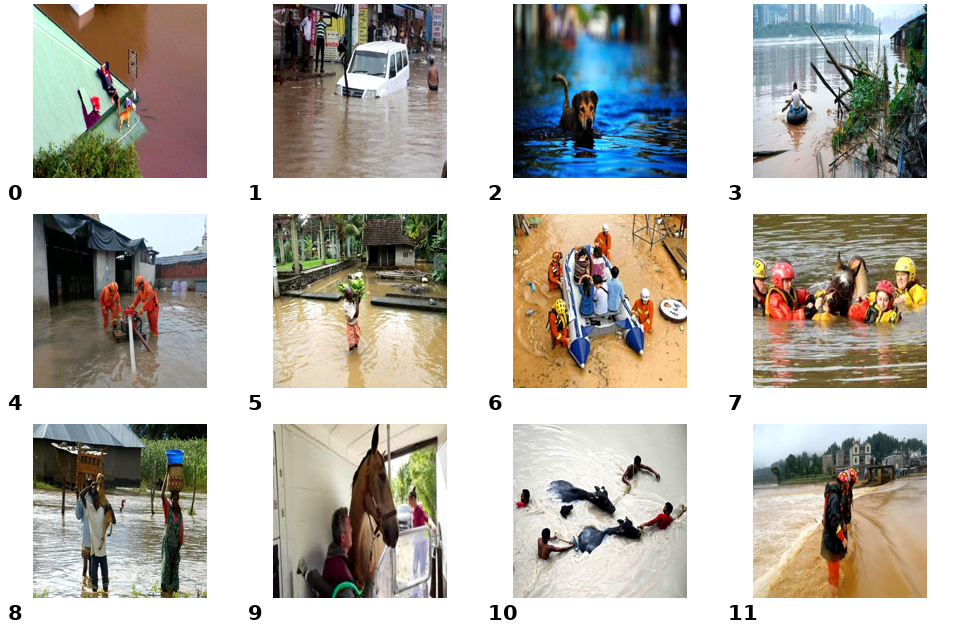

In [2]:
previous_preview = drawn['paths'] if 'drawn' in globals() else []
drawn = lottery(count=12, exclude_paths=previous_preview)
print('Seed:', drawn['seed'])
display(preview_sheet(drawn))

## Generate detection examples

Enter four distinct indices shown in the preview in `chosen_indices`. Leave the list empty to let the model evaluate all 12 images and select four automatically.

This cell runs inference and writes the mosaics, external image and video examples to `notebooks/generated/figures/`. It also updates the selection manifest.

In [3]:
chosen_indices = []  # Example: [0, 2, 5, 8]
manifest = generate(seed=drawn['seed'], source_paths=drawn['paths'], chosen_indices=chosen_indices)
for item in manifest['selected']:
    print(Path(item['path']).name, item['matched_classes'], max(d['confidence'] for d in item['detections']))
print('Manifest:', root / 'models/comparisons/qualitative-mosaic.json')

1015_jpg.rf.a4250654e0a28ee00d40371659e62672.jpg ['rescuer'] 0.8438
dog-flood-preparedness-1_jpg.rf.5f71c257b72944a500940606c3253c50.jpg ['dog'] 0.8424
224_jpg.rf.d1de8a46523dfd047a903d4b975df585.jpg ['civilian'] 0.7958
flood-india_jpg.rf.9511a1e8b24ffe17c6df0e6f68ab3717.jpg ['civilian'] 0.754
Manifest: /home/carol/urban-disaster-monitor/models/comparisons/qualitative-mosaic.json


## Review and reproduce the selection

Compare the original images and predictions below. The manifest records the seed, preview and selected images, bounding boxes, confidence scores and checkpoint hash. To reproduce the selection, load the manifest as `m` and use:

```python
generate(
    seed=m['seed'],
    source_paths=m['preview_paths'],
    chosen_indices=m['chosen_indices'],
    avoid_history=False,
)
```

In [ ]:
display(Image(filename=str(OUTPUT_DIR / 'mosaico_dataset.png'), width=640))
display(Image(filename=str(OUTPUT_DIR / 'mosaico_anotacoes.png'), width=640))